# Spherical Harmonic FOD Visualisation

This notebook visualises FODs represented with real even spherical harmonics, including default single, double, and triple crossing configurations.

The plotting and SH helper functions are imported from the core `dmri_models` package to keep notebook code minimal and reusable.

In [4]:
import numpy as np

from dmri_models import plot_fod_surface
from dmri_models.compartments import SphericalHarmonicFOD

In [5]:
# Reusable SH helpers and plotting are now available from dmri_models.
# This notebook focuses on choosing coefficients and visualising outputs.

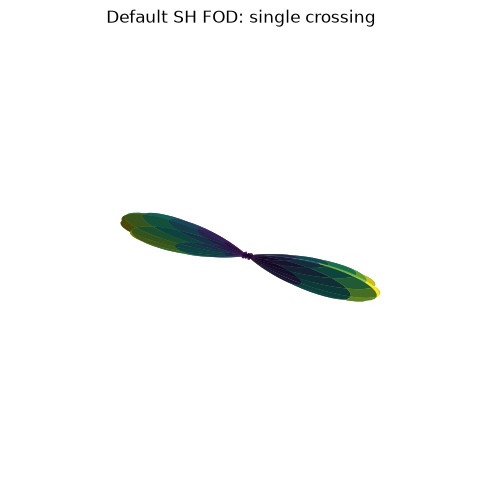

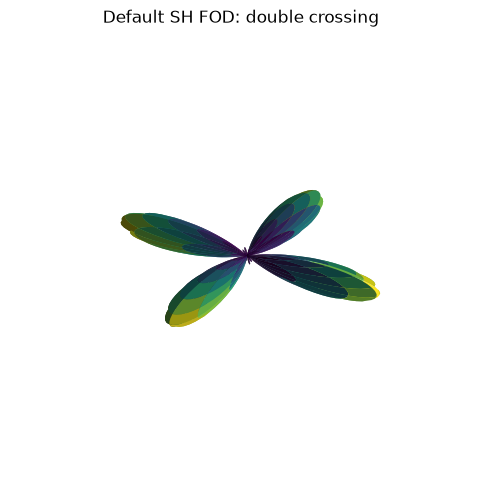

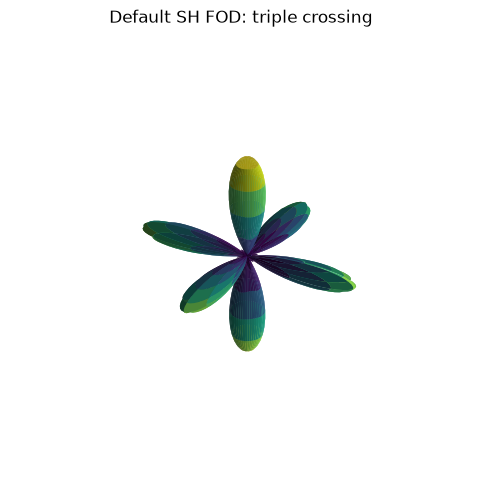

<Axes3D: title={'center': 'Default SH FOD: triple crossing'}>

In [6]:
l_max = 8
sh_fod = SphericalHarmonicFOD(
    coefficients="coeffs",
    l_max=l_max,
    include_l0=False,
    rectify=True,
)

single_crossing = SphericalHarmonicFOD.default_crossing_coefficients(
    l_max=l_max,
    crossing="single",
    include_l0=False,
    kappa=20.0,
)

double_crossing = SphericalHarmonicFOD.default_crossing_coefficients(
    l_max=l_max,
    crossing="double",
    include_l0=False,
    kappa=22.0,
)

triple_crossing = SphericalHarmonicFOD.default_crossing_coefficients(
    l_max=l_max,
    crossing="triple",
    include_l0=False,
    kappa=24.0,
)

plot_fod_surface("Default SH FOD: single crossing", sh_fod, single_crossing, coefficient_name="coeffs")
plot_fod_surface("Default SH FOD: double crossing", sh_fod, double_crossing, coefficient_name="coeffs")
plot_fod_surface("Default SH FOD: triple crossing", sh_fod, triple_crossing, coefficient_name="coeffs")

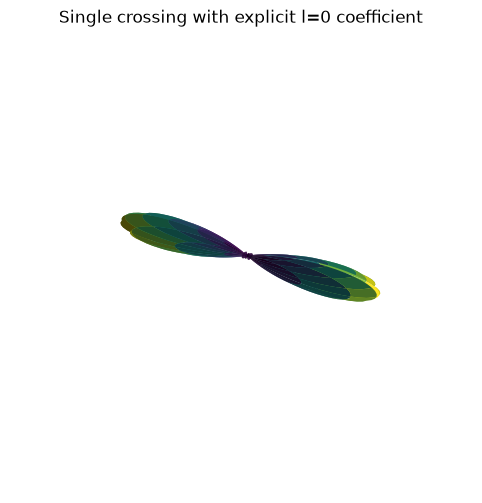

Normalised rotational invariants p_l:
[1.         0.85837416 0.58645633 0.33548489 0.12899607]


In [7]:
# Demonstrate include_l0=True coefficients and rotational invariants.
sh_fod_with_l0 = SphericalHarmonicFOD(
    coefficients="coeffs",
    l_max=l_max,
    include_l0=True,
    rectify=True,
)

single_crossing_full = SphericalHarmonicFOD.default_crossing_coefficients(
    l_max=l_max,
    crossing="single",
    include_l0=True,
    kappa=20.0,
)

plot_fod_surface(
    "Single crossing with explicit l=0 coefficient",
    sh_fod_with_l0,
    single_crossing_full,
    coefficient_name="coeffs",
)
print("Normalised rotational invariants p_l:")
print(sh_fod_with_l0.rotational_invariants({"coeffs": single_crossing_full}, normalise=True))

## Notes

- Both SH coefficient conventions are supported and normalised internally.
- Default crossing examples are generated by fitting SH coefficients to mixtures of Watson-like peaks.
- Negative values are clipped before plotting for visual stability.